In [1]:
import sys
# sys.path.insert(0, '../../Utilities/')

# from jax.example_libraries import optimizers
import jax.numpy as jnp
import numpy as np
from jax import grad, jit, vmap, value_and_grad, hessian
from jax import random
from functools import partial
import flax.linen as nn
import jax
import optax
import pickle
from datetime import datetime
import os
import numpy as np
from scipy import sparse
import time
from jax import grad, hessian, jit, vmap, pmap
from jax.tree_util import tree_leaves
from datetime import datetime
import matplotlib.pyplot as plt
import pickle
import flax.linen as nn
import optax
import optax.tree_utils as otu
from seq_minmax_opt_class import SeqMinMaxOptProb
from my_helpers import plot_u_2D, plot_comparison_seperate_combined_u_theta, compute_errors_combined_u_theta, plot_u_theta, plot_u_theta_mesh, plot_comparison_together
from PwpHex_class import PiecewiseLinearPolynomialsHex
from minmax_opt_class_mgnn_2d import MinMaxOptProb2D
from minmax_opt_class_mgnn import MinMaxOptProb

In [2]:
t_min = 0
t_max = 0.5
x_min = 0
x_max = 1
y_min = 0
y_max = 1

import numpy as np

def u_ref(t, x, y):
    """
    Exact solution u(t, x, y) for the 2D Burgers equation.
    """
    cond1 = x <= 0.5 - 3*t/5
    cond2 = (0.5 - 3*t/5 < x) & (x <= 0.5 - t/4)
    cond3 = (0.5 - t/4 < x) & (x <= 0.5 + t/2)
    cond4 = (0.5 + t/2 < x) & (x <= 0.5 + 4*t/5)
    cond5 = x > 0.5 + 4*t/5
    u = np.zeros_like(x)

    # Case 1
    cond1 = cond1
    u[cond1] = np.where(y[cond1] > 0.5 + 3*t[cond1]/20, -0.2, 0.5)

    # Case 2
    u[cond2] = np.where(y[cond2] > -8*x[cond2]/7 + 15/14 - 15*t[cond2]/28, -1, 0.5)

    # Case 3
    u[cond3] = np.where(y[cond3] > x[cond3]/6 + 5/12 - 5*t[cond3]/24, -1, 0.5)

    # Case 4
    u[cond4] = np.where(y[cond4] > x[cond4] - (5/(18*t[cond4])) * (x[cond4] + t[cond4] - 0.5)**2, -1, (2*x[cond4] - 1)/(2*t[cond4]))

    # Case 5
    u[cond5] = np.where(y[cond5] > 0.5 - t[cond5]/10, -1, 0.8)
    return u

def u0(x, y):
    """
    Initial condition u0(x, y).
    """
    return u_ref(t_min*np.zeros_like(x), x, y)

def u_left(t, y):
    """
    Boundary condition at x = x_min.
    """
    return u_ref(t, x_min*np.zeros_like(t), y)

def u_right(t, y):
    """
    Boundary condition at x = x_max.
    """
    return u_ref(t, x_max*np.ones_like(t), y)

def u_bottom(t, x):
    """
    Boundary condition at y = y_min.
    """
    return u_ref(t, x, y_min*np.zeros_like(t))

def u_top(t, x):
    """
    Boundary condition at y = y_max.
    """
    return u_ref(t, x, y_max*np.ones_like(t))

def res(u_quad, u_t, u_x, u_y):
    return u_t + u_quad * u_x + u_quad * u_y

N_t = 20
N_x = 9
N_y = 9
optprob = SeqMinMaxOptProb(
    input_dim=3, num_segments=3, 
    total_t_min=t_min, total_t_max=t_max, x_min=x_min, x_max=x_max, y_min=y_min, y_max=y_max,
    N_t=N_t, N_x=N_x, N_y=N_y, N_bc=128, N_ic=128,
    hidden_dims_list=[[64, 64, 64, 64, 64]], seed=0,
    sigma=10, N_perturb=50000, k_h_rf_times=2, f_adaptive_weight=2000, f_opt_kh=1,
    u0=u0, u1=u_left, u2=u_right, u3=u_bottom, u4=u_top, project="seq_minmax_burgers2D",
    lambda_ic=20.0, lambda_bc=20.0, lambda_eqn=1.0,
    gamma=0, N_test_gamma=1000, adjust_gamma=False,
    L1reg=0, sampling_method='uniform', notes='', pre_epochs=0,
    init_lrs=[1e-3, 1e-3, 1e-3], grade_epochs=[10000, 1000, 1000], decay_rates=[1e-3, 1e-3, 1e-3],
    res=res, loss_type='interior', k=0, f_plot=2000, partition='hex', u_ref=u_ref,
    set_wandb=False
)

Adding grade 1 with hidden dims [64, 64, 64, 64, 64]

Training segment [0.0000, 0.1667]
Skipping pre-training as pre_epochs is set to 0.

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
k_h_quad_all.shape: (50000, 8), u_quad.shape: (8,), residual.shape: (8,)
The largest W^{1,inf} norm of k_h coeffs is 7.585487
Grade 0, Iter 0, lambda_ic: 18.723894, lambda_bc: 18.327168, lambda_eqn: 1.079790
k_h_quad_all.shape: (50000, 8), u_quad.shape: (8,), residual.shape: (8,)
Grade 0, Iter 0, loss_eqn: 0.410826, loss_eqn_from_kh: 0.410656, loss_l1: 0.410656, loss_ibc: 2.542315


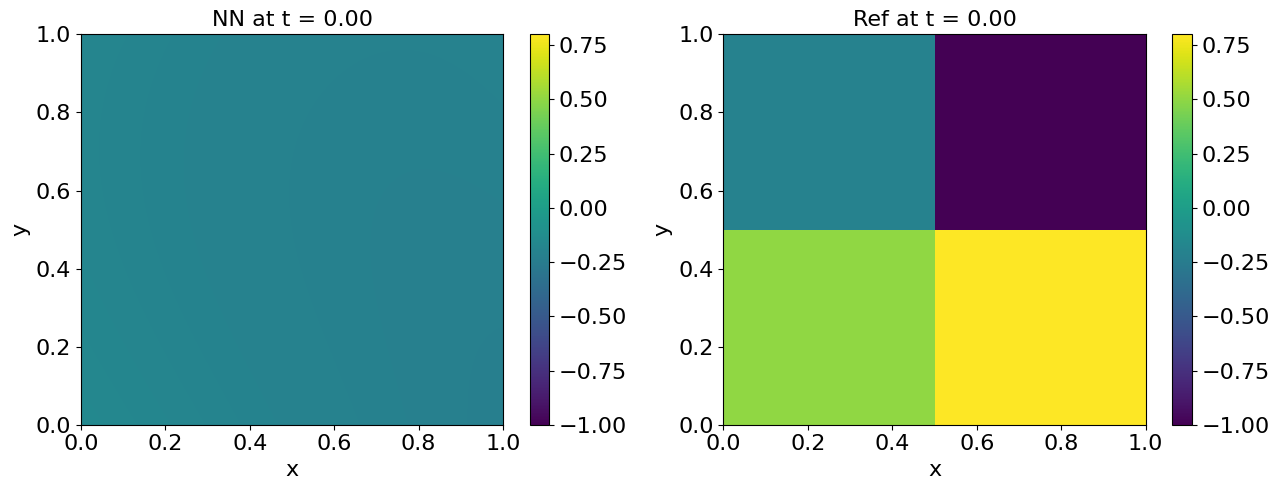

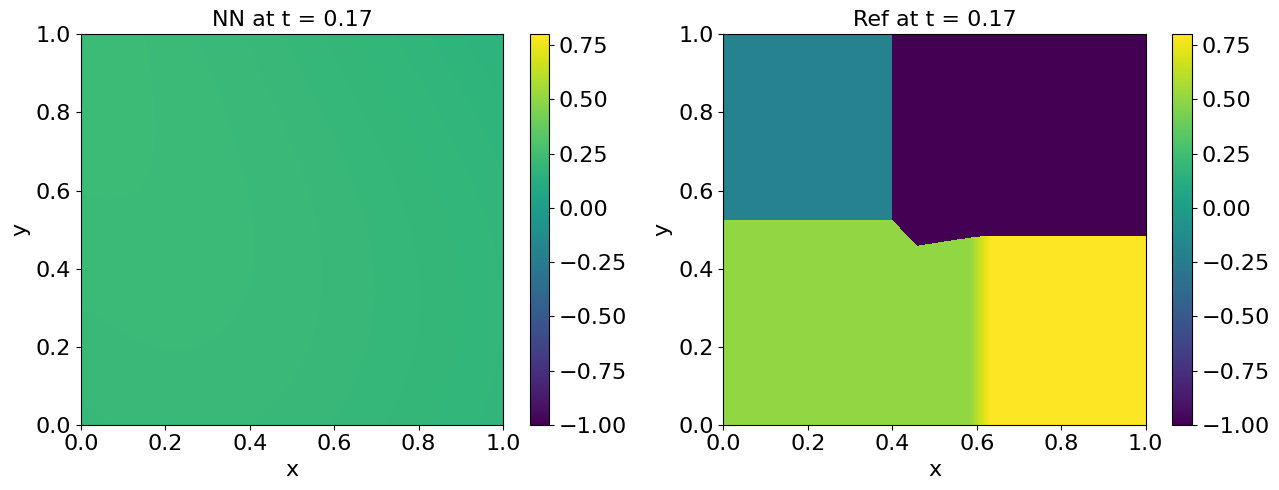

Grade 0, Iter 100, loss_eqn: 0.104723, loss_eqn_from_kh: 0.107090, loss_l1: 0.107094, loss_ibc: 0.512039


In [ ]:
optprob.train_seq()

In [5]:
optprob.pwp.quad_weights

Array([0., 0., 0., ..., 0., 0., 0.], dtype=float32)

In [5]:
jnp.dot(jnp.ones((1000,8)), jnp.ones(8)).shape

(1000,)

In [12]:
import numpy as np

def u_ref(t, x, y):
    """
    Reference solution u(t, x, y).
    Returns 0 if y > 0.5 + 0.5*t, else 1.
    """
    return np.where(y > 0.5 + 0.5 * t, 0, 1)

def u0(x, y):
    """
    Initial condition u0(x, y) = u(0, x, y).
    """
    return u_ref(t_min*np.zeros_like(x), x, y)

def u_left(t, y):
    """
    Boundary condition at x = x_min (independent of x, so same as u_ref).
    """
    return u_ref(t, np.zeros_like(y), y)  # x=0 as placeholder, since independent of x

def u_right(t, y):
    """
    Boundary condition at x = x_max (independent of x, so same as u_ref).
    """
    return u_ref(t, np.zeros_like(y), y)  # x=0 as placeholder

def u_bottom(t, x):
    """
    Boundary condition at y = y_min (independent of x, so same as u_ref with y=y_min).
    """
    return u_ref(t, x, np.zeros_like(x))  # y=0 as placeholder, but function needs y

def u_top(t, x):
    """
    Boundary condition at y = y_max (independent of x, so same as u_ref with y=y_max).
    """
    return u_ref(t, x, np.ones_like(x))  # y=0 as placeholder, adjust if y_max known

def res(u_quad, u_t, u_x, u_y):
    return u_t + u_quad * u_x + u_quad * u_y

In [13]:
t_min = 0
t_max = 0.5
x_min = 0
x_max = 1
y_min = 0
y_max = 1
N_t = 8
N_x = 9
N_y = 9
optprob = SeqMinMaxOptProb(input_dim=3, total_t_min=t_min, total_t_max=t_max, x_min=x_min, x_max=x_max, y_min=y_min, y_max=y_max,
    N_t=N_t, N_x=N_x, N_y=N_y, N_bc=128, N_ic=128,
    hidden_dims_list=[[64, 64, 64, 64, 64]], seed=0,
    sigma=10, N_perturb=50000, k_h_rf_times=2, f_adaptive_weight=2000, f_opt_kh=1,
    u0=u0, u1=u_left, u2=u_right, u3=u_bottom, u4=u_top, project="seq_minmax_burgers2D",
    lambda_ic=20.0, lambda_bc=20.0, lambda_eqn=1.0,
    gamma=0, N_test_gamma=1000, adjust_gamma=False,
    L1reg=0, sampling_method='uniform', notes='', pre_epochs=0,
    init_lrs=[2e-4, 1e-3, 1e-3], grade_epochs=[101, 1000, 1000], decay_rates=[1e-3, 1e-3, 1e-3],
    res=res, loss_type='interior', k=0, f_plot=2000, partition='hex', u_ref=u_ref,
    set_wandb=False
)

Adding grade 1 with hidden dims [64, 64, 64, 64, 64]

Training segment [0.0000, 0.5000]
Skipping pre-training as pre_epochs is set to 0.

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
The largest W^{1,inf} norm of k_h coeffs is 9.413791
Grade 0, Iter 0, lambda_ic: 18.335306, lambda_bc: 18.339373, lambda_eqn: 1.145638
Grade 0, Iter 0, loss_eqn: 0.410825, loss_eqn_from_kh: 0.410592, loss_l1: 0.410592, loss_ibc: 3.018623


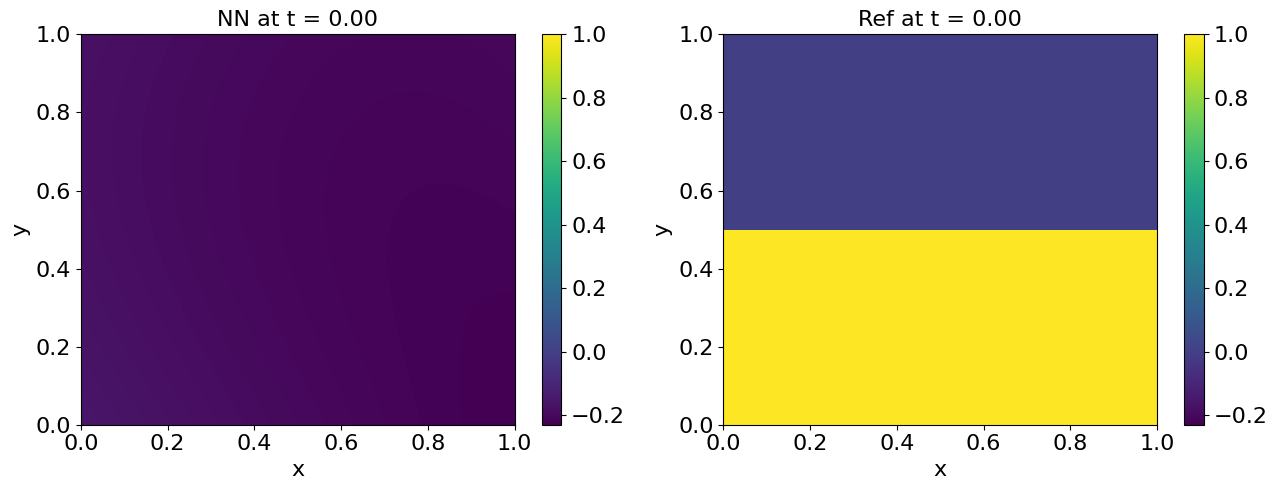

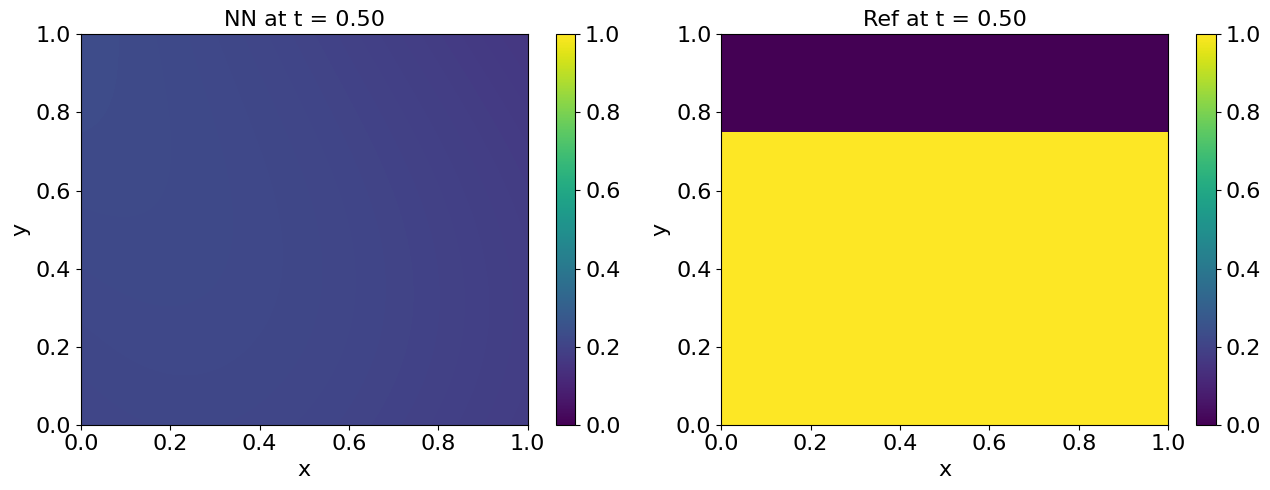

Grade 0, Iter 100, loss_eqn: 0.234396, loss_eqn_from_kh: 0.234049, loss_l1: 0.234049, loss_ibc: 0.275619
Train time for stage1: 92.617730 seconds

Plotting after training segment [0.0000, 0.5000]


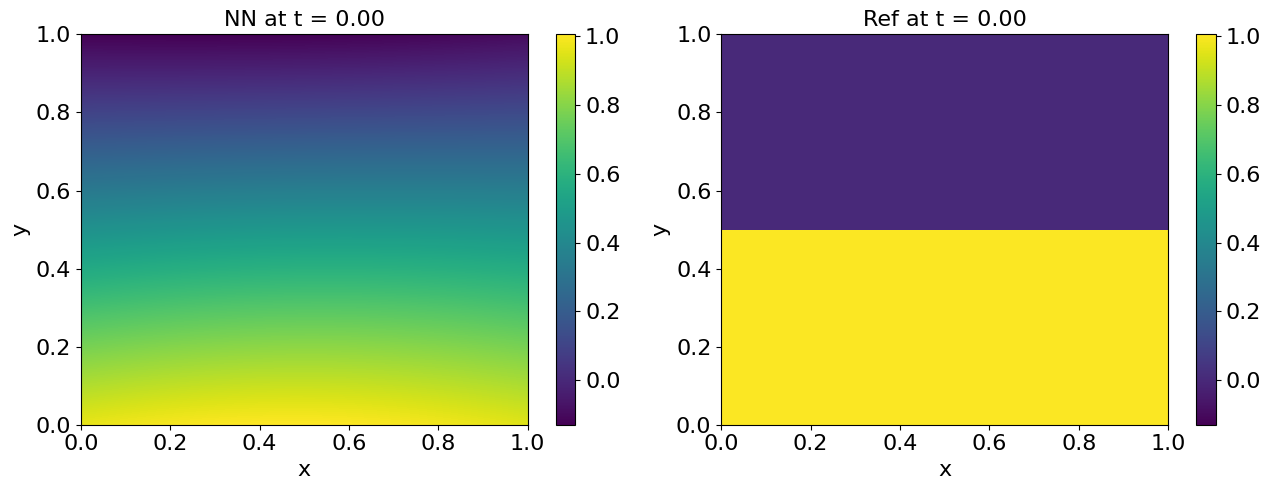

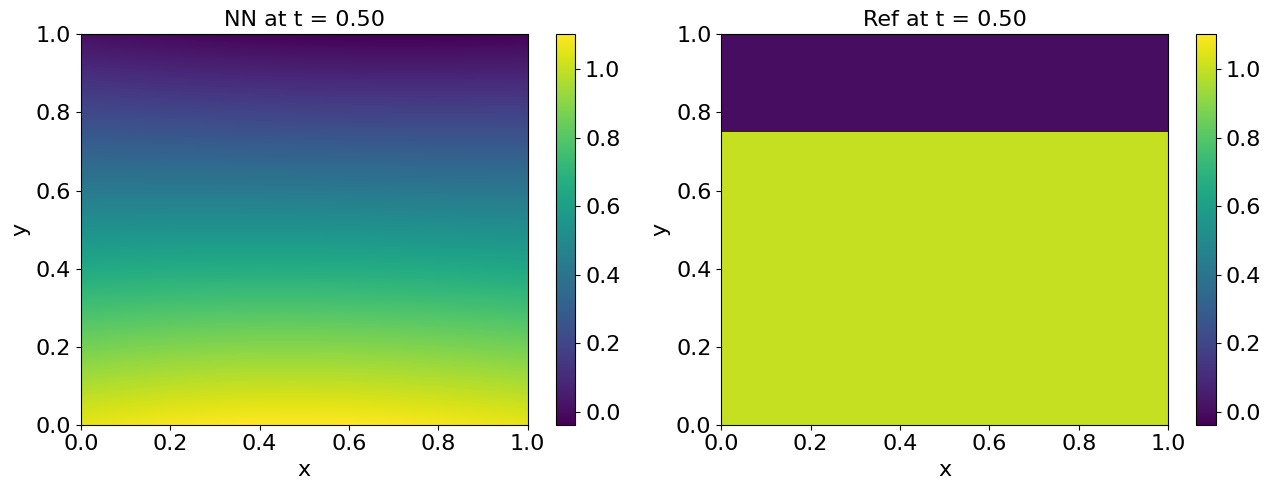

In [14]:
optprob.train_seq()

In [7]:
self = optprob.segments[0]
self.input_dim
self.u_ref(0.5, 1, 0.5)

IndexError: list index out of range

In [ ]:
plot_u_2D([0, 0.5], u_ref, nx=1000, ny=1000)

In [8]:
self = optprob
params = optprob.model.mlps[0].params
self.gen_funcs(0)
self.pwp.coeffs, self.key, loss_eqn_from_kh, loss_l1, loss_each_elem = self.maximize_kh_step(params, self.key)

In [9]:
Nt = self.pwp.N_elements
quad_points = self.pwp.quad_points_parti
u_values_all = self.u_eval(params, quad_points)
quad_weights = self.pwp.quad_weights_parti
avg_vals = jnp.einsum('ij,ij->i', u_values_all, quad_weights)/self.elem_meas
init_coeffs_all = jnp.hstack([avg_vals[..., None] , jnp.zeros((Nt, self.p_dof - 1))])
perturbations_all = self.sigma * jax.random.uniform(self.key, (self.N_perturb, self.p_dof), minval=-1, maxval=1)
perturbed_coeffs_all = init_coeffs_all[:, None, :] + perturbations_all[None, :, :]

In [35]:
parti_idx = 0
quad_points = self.pwp.quad_points_parti[parti_idx]
quad_weights = self.pwp.quad_weights_parti[parti_idx]
u_quad = self.u_eval(params, quad_points)
grad_u_tx = self.grad_u(params, quad_points)

In [36]:
quad_points.shape

(64, 3)

In [11]:
u_t, u_x, u_y = grad_u_tx[:, 0], grad_u_tx[:, 1], grad_u_tx[:, 2]
residual = self.res(u_quad, u_t, u_x, u_y).flatten()
p_coeffs_all = perturbed_coeffs_all[parti_idx]
k_h_quad_all = (p_coeffs_all[:, 0][:, None] + 
                p_coeffs_all[:, 1][:, None] * quad_points[:, 0] + 
                p_coeffs_all[:, 2][:, None] * quad_points[:, 1] + 
                p_coeffs_all[:, 3][:, None] * quad_points[:, 2]
               )
k_h_quad_all1 = jnp.einsum('ik,kj->ij', p_coeffs_all[:, 1:], quad_points.T) + p_coeffs_all[:, 0][:, None]

In [12]:
jnp.min(k_h_quad_all1-k_h_quad_all)

Array(-9.536743e-07, dtype=float32)

In [33]:
quad_points = self.pwp.quad_points
p_coeffs_quad = self.pwp.coeffs[self.pwp.element_indices]
k_h_quad = p_coeffs_quad[:, 0] + jnp.sum(p_coeffs_quad[:, 1:] * quad_points, axis=1)
k_h_quad1 = jnp.einsum('ij, ij->i', p_coeffs_quad[:, 1:], quad_points) + p_coeffs_quad[:, 0]

In [34]:
jnp.max(jnp.abs(k_h_quad-k_h_quad1))

Array(0., dtype=float32)

In [ ]:
jnp.max(k_h_quad-k_h_quad1)

In [28]:
jnp.sum(p_coeffs_quad[:, 1:] * quad_points, axis=1).shape

(41472,)

In [37]:
self.pwp.quad_points.shape

(41472, 3)

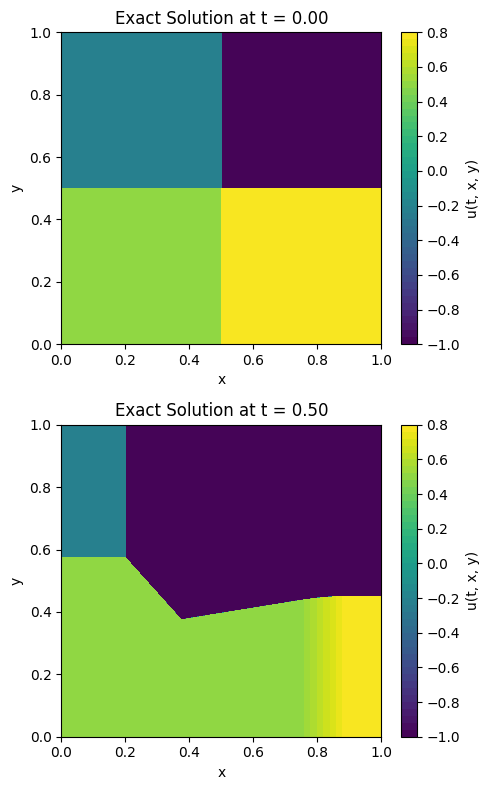

In [12]:
plot_u_2D([0, 0.5], u_ref, nx=1000, ny=1000)

In [77]:
N_t = 10  # Divisions in t
N_x = 5  # Divisions in x
N_y = 2  # Divisions in y
t_min = 0.0
t_max = 1
x_min = -1.0
x_max = 1.0
y_min = 0.0
y_max = 2.0

tau = (t_max - t_min) / N_t
hx = (x_max - x_min) / N_x
hy = (y_max - y_min) / N_y
t_starts = jnp.linspace(t_min, t_max - tau, N_t)
x_starts = jnp.linspace(x_min, x_max - hx, N_x)
y_starts = jnp.linspace(y_min, y_max - hy, N_y)
tl, xl, yl = jnp.meshgrid(t_starts, x_starts, y_starts, indexing='ij')
# Define the 8 vertices for each hexahedron using binary offsets
offsets_bin = jnp.array([[int(b) for b in f'{i:03b}'] for i in range(8)], dtype=jnp.float32)  # (8,3) binary 000 to 111
deltas = jnp.array([tau, hx, hy])
offsets = offsets_bin * deltas  # (8,3)
lowers = jnp.stack([tl.ravel(), xl.ravel(), yl.ravel()], axis=1)[:, None, :]  # (N_elements, 1, 3)
partitions = lowers + offsets[None, :, :]  # (N_elements, 8, 3)

In [83]:
tl, xl, yl = jnp.meshgrid(t_starts, x_starts, y_starts)
xl.shape

(5, 10, 2)

In [82]:
tl

Array([[[0. , 0. ],
        [0.1, 0.1],
        [0.2, 0.2],
        [0.3, 0.3],
        [0.4, 0.4],
        [0.5, 0.5],
        [0.6, 0.6],
        [0.7, 0.7],
        [0.8, 0.8],
        [0.9, 0.9]],

       [[0. , 0. ],
        [0.1, 0.1],
        [0.2, 0.2],
        [0.3, 0.3],
        [0.4, 0.4],
        [0.5, 0.5],
        [0.6, 0.6],
        [0.7, 0.7],
        [0.8, 0.8],
        [0.9, 0.9]],

       [[0. , 0. ],
        [0.1, 0.1],
        [0.2, 0.2],
        [0.3, 0.3],
        [0.4, 0.4],
        [0.5, 0.5],
        [0.6, 0.6],
        [0.7, 0.7],
        [0.8, 0.8],
        [0.9, 0.9]],

       [[0. , 0. ],
        [0.1, 0.1],
        [0.2, 0.2],
        [0.3, 0.3],
        [0.4, 0.4],
        [0.5, 0.5],
        [0.6, 0.6],
        [0.7, 0.7],
        [0.8, 0.8],
        [0.9, 0.9]],

       [[0. , 0. ],
        [0.1, 0.1],
        [0.2, 0.2],
        [0.3, 0.3],
        [0.4, 0.4],
        [0.5, 0.5],
        [0.6, 0.6],
        [0.7, 0.7],
        [0.8, 0.8],
        [0.9

In [69]:
# Gauss-Legendre nodes and weights in [-1, 1]
nodes, weights = np.polynomial.legendre.leggauss(3)
nodes_jnp = jnp.array(nodes)
weights_jnp = jnp.array(weights)

# Tensor product for 3D
t_nodes, x_nodes, y_nodes = jnp.meshgrid(nodes_jnp, nodes_jnp, nodes_jnp)

In [79]:
tl, xl, yl = jnp.meshgrid(t_starts, x_starts, y_starts, indexing='ij')
tl.shape

(10, 5, 2)

In [72]:
t_nodes

Array([[[-0.7745967, -0.7745967, -0.7745967],
        [ 0.       ,  0.       ,  0.       ],
        [ 0.7745967,  0.7745967,  0.7745967]],

       [[-0.7745967, -0.7745967, -0.7745967],
        [ 0.       ,  0.       ,  0.       ],
        [ 0.7745967,  0.7745967,  0.7745967]],

       [[-0.7745967, -0.7745967, -0.7745967],
        [ 0.       ,  0.       ,  0.       ],
        [ 0.7745967,  0.7745967,  0.7745967]]], dtype=float32)

In [73]:
x_nodes

Array([[[-0.7745967, -0.7745967, -0.7745967],
        [-0.7745967, -0.7745967, -0.7745967],
        [-0.7745967, -0.7745967, -0.7745967]],

       [[ 0.       ,  0.       ,  0.       ],
        [ 0.       ,  0.       ,  0.       ],
        [ 0.       ,  0.       ,  0.       ]],

       [[ 0.7745967,  0.7745967,  0.7745967],
        [ 0.7745967,  0.7745967,  0.7745967],
        [ 0.7745967,  0.7745967,  0.7745967]]], dtype=float32)

In [74]:
y_nodes

Array([[[-0.7745967,  0.       ,  0.7745967],
        [-0.7745967,  0.       ,  0.7745967],
        [-0.7745967,  0.       ,  0.7745967]],

       [[-0.7745967,  0.       ,  0.7745967],
        [-0.7745967,  0.       ,  0.7745967],
        [-0.7745967,  0.       ,  0.7745967]],

       [[-0.7745967,  0.       ,  0.7745967],
        [-0.7745967,  0.       ,  0.7745967],
        [-0.7745967,  0.       ,  0.7745967]]], dtype=float32)